In [1]:
using Flux
using CUDA, cuDNN
using StatsPlots
using Plots; default(fontfamily="Computer Modern", framestyle=:box) # LaTex-style
using Random
using LaTeXStrings
using Logging; 
using ProgressMeter
using StatsBase
using LinearAlgebra
using ParameterSchedulers
using LoggingExtras
using MosaicViews
using NPZ
using Images

In [24]:
include("./utils.jl")
include("./io_utils.jl")
global_logger(cudnn_filter)

ActiveFilteredLogger{SimpleLogger, var"#23#24"}(var"#23#24"(), SimpleLogger(VSCodeServer.IJuliaCore.IJuliaStdio{Base.PipeEndpoint, typeof(VSCodeServer.io_send_callback)}(IOContext(Base.PipeEndpoint(RawFD(23) open, 0 bytes waiting)), VSCodeServer.io_send_callback), ReentrantLock(), Info, Dict{Any, Int64}()))

In [3]:
begin
    # Define the device selector based on availability
    const device = CUDA.functional() ? gpu : cpu
    
    if CUDA.functional()
        @info "🚀 Functional GPU detected! Setting device to CUDA."
    else
        @warn "💻 No GPU found. Falling back to host CPU."
    end
end

┌ Info: 🚀 Functional GPU detected! Setting device to CUDA.
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W2sdnNjb2RlLXJlbW90ZQ==.jl:6


In [4]:
mnist_binary_loader, mnist_binary_test, mnist_binary_valid = load_binary_mnist_data(1000; tensor_shape = (28^2, :))

(DataLoader(data::Tuple{SubArray{Bool, 2, BitMatrix, Tuple{Base.Slice{Base.OneTo{Int64}}, UnitRange{Int64}}, true}}, shuffle=true, batchsize=1000), Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0], Bool[0 0 … 0 0; 0 0 … 0 0; … ; 0 0 … 0 0; 0 0 … 0 0])

In [5]:
struct DeepNADEInputWrapper
    with_mask::Bool
end
Flux.@layer DeepNADEInputWrapper # Registers the layer with Flux's backend

# Expects a tuple or pair containing (x, mask)
function (m::DeepNADEInputWrapper)((x, mask))
    if m.with_mask
        return vcat(x .* mask, mask)
    else
        return x .* mask
    end
end

In [6]:
begin
    struct DeepNADE{T<:Flux.Chain}
        d::Int
        with_mask::Bool
        net::T
        rnade::Bool
        K::Int
    end

    Flux.@layer DeepNADE trainable = (net,)


    # function DeepNADE(d::Int=28^2, with_mask::Bool=true, rande::Bool = false, K::Int = 3)
    #     # network = Chain(Dense((with_mask ? 2 : 1) * d => 500 , relu), Dense(500 => d))
    #     # return DeepNADE(d, with_mask, network)
    #     DeepNADE(d, with_mask, [500, 500], relu; rnade = rnade, K = K)
    # end


    function DeepNADE(d::Int=28^2, with_mask::Bool=true, hidden_sizes::Vector{Int}=[500, 500], act=relu; rnade::Bool = false, K::Int = 3)
        # network = Chain(Dense((with_mask ? 2 : 1) * d => 500 , relu), Dense(500 => d))
        input_size = (with_mask ? 2 : 1) * d
        output_size = rnade ? (3 * K * d) : d
        hidden_sizes = [input_size, hidden_sizes..., output_size]
        net = []
        for l in 1:(length(hidden_sizes)-1)
            if l == length(hidden_sizes)-1
                push!(net, Dense(hidden_sizes[l] => hidden_sizes[l+1]))
            else
                push!(net, Dense(hidden_sizes[l] => hidden_sizes[l+1], act))
            end
        end
        input_wrapper = DeepNADEInputWrapper(with_mask)
        network = Chain(input_wrapper, net...)
        return DeepNADE(d, with_mask, network, rnade, K)
    end


    # (m::DeepNADE)(xs) = m.net(xs)

    (m::DeepNADE)((xs, masks)) = m.net((xs, masks))
end

In [7]:
begin

    const gaussian_nconst = 1.0f0 / sqrt(2.0f0 * π)
    const log_gaussian_nconst = log(1.0f0 / sqrt(2.0f0 * π))
        
    function logpdf_gaussians(μs, σs, xs)
        diff = (μs .- xs) ./ σs
        sqerr = -0.5f0 * diff .^ 2
        return log_gaussian_nconst .+ sqerr .- log.(σs)
    end


    function logpdf_MoG(logπs, μs, σs, xs)
        result = logpdf_gaussians(μs, σs, xs) .+ logπs
        result = logsumexp(result, dims=1)
        return result
    end

end

logpdf_MoG (generic function with 1 method)

In [8]:
function loglik_MoG_from_net(outputs, xs; K = 3)
    d, batch_size = size(xs)
    pars_per_d = 3
    outputs = reshape(outputs, K, d, pars_per_d, batch_size)
    logπs = logsoftmax(outputs[:, :, 1, :], dims = 1)
    μs = outputs[:, :, 2, :]
    lnσs = outputs[:, :, end, :]
    σs = softplus.(lnσs)
    ## returns a d × batch_size matrix, i.e. ll per pixel per sample
    logLiks_d = logpdf_MoG(logπs, μs, σs, reshape(xs, 1, size(xs)...))[1, :, :] 
end

loglik_MoG_from_net (generic function with 1 method)

In [9]:
function logpdf(model::DeepNADE, xs; reduction=mean, ensemble_size=1, one_order=true)
    n = size(xs)[2]
    total_d = model.d
    logliks = zeros32(ensemble_size, n) |> device
    for e in 1:ensemble_size
        masks = fill(false, size(xs)...) |> device
        if one_order
            orders = repeat(shuffle(1:total_d)', n)'
        else
            orders = hcat([shuffle(1:total_d) for _ in 1:n]...)
        end
        ll = zeros(n) |> device
        for d in 1:total_d
            # if model.with_mask 
            #     preds = model(vcat(xs .* masks, masks))
            # else
            #     preds = model(xs .* masks)
            # end
            preds = model((xs, masks))
            if model.rnade
                ll +=  loglik_MoG_from_net(preds, xs; K = model.K)[CartesianIndex.(orders[d, :], 1:n)]
            else
                ll += - Flux.logitbinarycrossentropy(preds[CartesianIndex.(orders[d, :], 1:n)], xs[CartesianIndex.(orders[d, :], 1:n)]; agg=identity)
            end
            masks[CartesianIndex.(orders[d, :], 1:n)] .= true
        end
        logliks[e, :] = ll
    end
    (logsumexp(logliks, dims=1) .- log(Float32(ensemble_size))) |> reduction
end

function logpdf_val(model::DeepNADE, xs; reduction=mean)
    n = size(xs)[2]
    total_d = model.d
    orders = hcat([shuffle(1:total_d) for _ in 1:n]...)
    # ds = Int(ceil(total_d ./ 2)) * ones(Int, n)
    ds = rand(1:total_d, n)
    # orders .< ds'
    masks = (orders .< ds') |> device
    # if model.with_mask
    #     xs_input = vcat(xs .* masks, masks)
    # else
    #     xs_input = xs .* masks
    # end
    preds = model((xs, masks))
    negative_masks = .!masks
    if model.rnade
        logLiks = loglik_MoG_from_net(preds, xs; K = model.K) .* negative_masks
    else
        logLiks = -sum(Flux.logitbinarycrossentropy(preds, xs; agg=identity) .* negative_masks, dims=1)
    end
    num_of_pixels = sum(negative_masks, dims=1)
    (logLiks ./ num_of_pixels) * total_d |> mean
end


function sample(model::DeepNADE, n=1; sample_data = true)
    total_d = model.d
    xs_samples = zeros(Float32, total_d, n) |> device
    ps_samples = similar(xs_samples, Float32, total_d, n)
    masks = fill(false, size(xs_samples)...) |> device
    orders = hcat([shuffle(1:total_d) for _ in 1:n]...)
    for d = 1:total_d
        # if model.with_mask
        #     outputs = model(vcat(xs_samples .* masks, masks))
        # else
        #     outputs = model(xs_samples .* masks)
        # end
        outputs = model((xs_samples, masks))
        if model.rnade
            outputs = reshape(outputs, model.K, total_d, 3, n)
            πs = softmax(outputs[:, :, 1, :], dims = 1)[:, CartesianIndex.(orders[d, :], 1:n)]
            μs = outputs[:, :, 2, :][:, CartesianIndex.(orders[d, :], 1:n)]
            lnσs = outputs[:, :, end, :][:, CartesianIndex.(orders[d, :], 1:n)]
            σs = softplus.(lnσs)
            assignments = 1 .+ sum(rand_like(πs[1:1,:]) .> cumsum(πs, dims=1), dims=1) ## sample each pi column-wisely
            μzs = μs[CartesianIndex.(assignments[:], 1:n)]
            σzs = σs[CartesianIndex.(assignments[:], 1:n)]
			xs_samples[CartesianIndex.(orders[d, :], 1:n)] = (randn_like(σzs) .* σzs) .+ μzs
            ps_samples[CartesianIndex.(orders[d, :], 1:n)] = sum(μs .* πs, dims=1)[:]
        else
            ps = outputs[CartesianIndex.(orders[d, :], 1:n)] .|> sigmoid
            # x_pixels = (rand32(size(ps)...) |> device) .< ps
            x_pixels = rand_like(ps) .< ps
            xs_samples[CartesianIndex.(orders[d, :], 1:n)] = x_pixels
            ps_samples[CartesianIndex.(orders[d, :], 1:n)] = ps
        end
        
        masks[CartesianIndex.(orders[d, :], 1:n)] .= true
    end

    if sample_data
        return xs_samples
    else
        return ps_samples
    end
end

sample (generic function with 2 methods)

In [10]:
function fit!(model::DeepNADE, data_loader, optim=Adam(3f-4), max_epochs=50; verbose=true, learning_rate_decay=false, validation_data=nothing, patience=Inf, every_epoch = 10)
    total_d = model.d
    par_size_per_d = 3 ## 3 parameter per pixel for K=k component of a GoM likelihood, i.e. π_k, μ_k, σ_k
    batch_size = data_loader.batchsize
    with_mask = model.with_mask
    initial_lr = optim.eta ## initial learning rate
    if learning_rate_decay 
        total_batches_per_epoch = length(data_loader)
        total_steps = max_epochs * total_batches_per_epoch
        # step_interval = total_batches_per_epoch * epochs_per_drop
        # # linear_schedule = ParameterSchedulers.Stateful(Poly(start=initial_lr, degree=1, max_iter=total_steps))
        # schedule = ParameterSchedulers.Stateful(Step(start=initial_lr, decay=decay_rate, step_sizes=step_interval))
        # 1. Calculate your steps based on your data loop
        warmup_steps = Int(ceil(0.1 * total_steps))   # e.g., 10% of your training loop
        decay_steps = total_steps - warmup_steps  # The remaining steps in your training loop
        # 2. Define the two phases
        ss = WarmupLinear(1e-6, Float64(initial_lr), warmup_steps, total_steps, CosAnneal(Float64(initial_lr), 1e-6, decay_steps))

        # 3. Combine them chronologically into a single schedule
        schedule = ParameterSchedulers.Stateful(ss)
    end
    opt = Flux.setup(optim, model)
    losses = []
    mask_buffer = zeros(Bool, total_d, batch_size)
    validation_check = false
    best_model = deepcopy(model) # To save a checkpoint of the best model
    if !isnothing(validation_data)
        # Trackers for early stopping
        validation_check = true
        best_val_loss = Inf
        epochs_no_improve = 0
    end
    @showprogress for epoch in 1:max_epochs
        for (xs,) in data_loader
            batch_size_real = size(xs)[2] ## in case mismatch size at the end
            cs = Array{Int}(undef, 1, batch_size_real)
            for i in 1:batch_size_real
                ## 1. Uniformly pick exactly how many pixels this sample will see (0 to total d - 1)
                c = rand(0:(total_d-1))
                cs[1, i] = c
                ## 2. Fill the column sequentially with the perfect number of 1s and 0s
                @views mask_buffer[1:c, i] .= true
                @views mask_buffer[(c+1):end, i] .= false
                ## 3. Shuffle this sample's column in-place. 
                ## This randomizes the coordinate layout with 0 allocations.
                @views shuffle!(mask_buffer[:, i])
            end
            mask_buffer_gpu = mask_buffer[:, 1:batch_size_real] |> device
            negative_masks = .!mask_buffer_gpu
            xs_gpu = xs |> device
            # xs_masked = (mask_buffer_gpu .* xs_gpu) |> device
            # if with_mask
            #     xs_masked = vcat(xs_masked, mask_buffer_gpu)
            # end

            li, gs = Flux.withgradient(model) do m
                preds = m((xs_gpu, mask_buffer_gpu))
                if m.rnade
                    ## returns a d × batch_size matrix, i.e. ll per pixel per sample
                    logLiks_d = - loglik_MoG_from_net(preds, xs_gpu; K=m.K)
                else
                    logLiks_d = Flux.logitbinarycrossentropy(preds, xs_gpu; agg=identity)
                end
                logLiks = sum(logLiks_d .* negative_masks, dims=1)
                num_of_pixels = sum(negative_masks, dims=1)
                (logLiks ./ num_of_pixels) * total_d |> mean
            end

            Flux.update!(opt, model, gs[1])
            push!(losses, li)


            if learning_rate_decay 
                next_lr = ParameterSchedulers.next!(schedule)
                Flux.adjust!(opt, next_lr)
            end
        end

        # --- VALIDATION PHASE (End of Epoch) ---
        if validation_check
            current_val_loss = -logpdf_val(model, validation_data |> device)


            # --- EARLY STOPPING LOGIC ---
            if current_val_loss < best_val_loss
                # New best found! Reset patience tracker and save parameters
                best_val_loss = current_val_loss
                best_model = deepcopy(model |> cpu) # Save snapshot
                epochs_no_improve = 0
            else
                # No improvement, increment counter
                epochs_no_improve += 1
            end

            # Check if patience has run out
            if epochs_no_improve >= patience
                # initial_lr *= 0.5
                # Flux.adjust!(opt, eta=initial_lr)
                @info "🛑 Early stopping triggered! No improvement for $patience epochs."
                # println("🏆 Best Validation Loss achieved: $(round(best_val_loss, digits=5))")
                # epochs_no_improve = 0
                break
            end
        end

        if verbose && (epoch % every_epoch) == 1
            @info "Epoch $(epoch); Loss = $(round(losses[end]; digits=4))"
        end
    end
    return losses, best_model
end

fit! (generic function with 3 methods)

In [11]:
begin
    # AdamW(0.005; couple =false)
    Random.seed!(2345)
    dpnade_model = DeepNADE(28^2, true) |> device
    # losses_dnade, best_dpnade_model = fit!(dpnade_model, mnist_binary_loader, AdamW(0.001, (0.9, 0.999), 0.0; couple=false), 500; learning_rate_decay=false, validation_data=mnist_binary_valid, patience=Inf, every_epoch = 50)
    losses_dnade, best_dpnade_model = fit!(dpnade_model, mnist_binary_loader, Adam(0.001), 500; learning_rate_decay=true, validation_data=mnist_binary_valid, patience=Inf, every_epoch=20)

end

┌ Info: Epoch 1; Loss = 468.619
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_X11sdnNjb2RlLXJlbW90ZQ==.jl:107
Progress:   4%|█▋                                       |  ETA: 0:31:13┌ Info: Epoch 21; Loss = 126.3218
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_X11sdnNjb2RlLXJlbW90ZQ==.jl:107
Progress:   8%|███▎                                     |  ETA: 0:16:56┌ Info: Epoch 41; Loss = 110.3292
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_X11sdnNjb2RlLXJlbW90ZQ==.jl:107
Progress:  12%|████▉                                    |  ETA: 0:12:05┌ Info: Epoch 61; Loss = 102.6489
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_X11sdnNjb2RlLXJlbW90ZQ==.jl:107
Progress:  16%|██████▌                                  |  ETA: 0:09:32┌ Info: Epoch 81; Loss = 98.2281
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34

(Any[555.69116f0, 502.59824f0, 504.31863f0, 502.43512f0, 503.33197f0, 503.7677f0, 503.91528f0, 502.95663f0, 502.1224f0, 502.47818f0  …  85.17763f0, 90.51873f0, 85.236176f0, 88.098434f0, 87.28845f0, 86.60479f0, 86.115326f0, 87.251526f0, 87.335045f0, 86.816666f0], DeepNADE{Chain{Tuple{DeepNADEInputWrapper, Dense{typeof(relu), Matrix{Float32}, Vector{Float32}}, Dense{typeof(relu), Matrix{Float32}, Vector{Float32}}, Dense{typeof(identity), Matrix{Float32}, Vector{Float32}}}}}(784, true, Chain(DeepNADEInputWrapper(true), Dense(1568 => 500, relu), Dense(500 => 500, relu), Dense(500 => 784)), false, 3))

In [12]:
logpdf_val(dpnade_model, mnist_binary_test |> device)

-90.17362f0

In [13]:
logpdf(dpnade_model, mnist_binary_test |> device; ensemble_size=1, one_order=true)

-90.0499f0

In [14]:
logpdf(dpnade_model, mnist_binary_test |> device; ensemble_size=20, one_order=false)

-86.425934f0

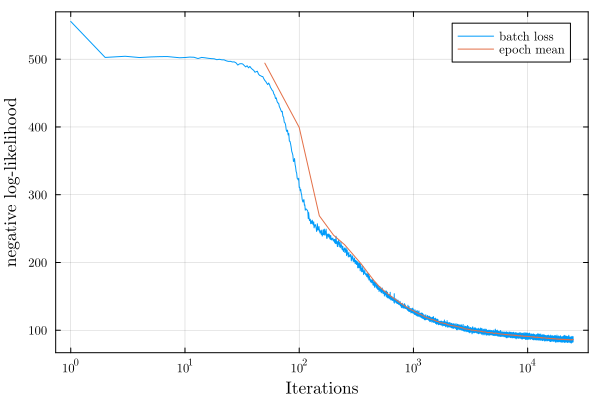

In [25]:
plot_loss(losses_dnade, length(mnist_binary_loader))

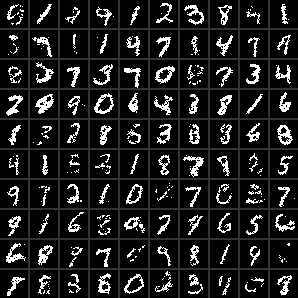

In [16]:
begin
    # Random.seed!(1234)
    # # Random.seed!(CUDA.default_rng(), 1234) # Seeds the GPU
    # CUDA.seed!(1234) 
    set_rand_seed(1234)
    sampled_data = sample(dpnade_model, 100)
    vec2imgs(sampled_data; nrows=10)
end

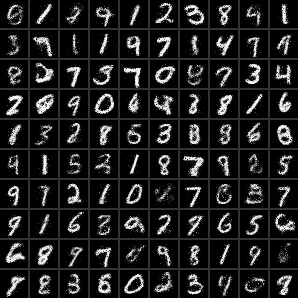

In [17]:
begin
    set_rand_seed(1234)
    vec2imgs(sample(dpnade_model, 100; sample_data = false); nrows=10)
end

In [18]:
begin
    include("./generate_data.jl")
	Random.seed!(1234)
	# --- Data Generation ---
	noise_level = 0.06
	n_points = 1000
	data_moons = generate_moons(n_points * 2; noise = noise_level)
	data_circles = generate_circles(n_points * 2; noise = noise_level)
	data_ring = generate_gaussian_ring(n_points * 2; noise = noise_level * 3)
	data_spiral = generate_spiral(n_points * 2; noise = noise_level)
	data_ribbon = generate_toy_dataset_1(n_points * 2)
end;

In [19]:
begin

    data_2d_raw = Dict("moon" => data_moons, "circles" => data_circles, 
        "ring" => data_ring, "spiral" => data_spiral, "ribbon" => data_ribbon)  

    tf_2d = Dict()
    data_2d_test = Dict()
    data_2d_train_loaders = Dict()
    batch_size = 200
    for (name, data) in data_2d_raw
        data_train = data[:, 1:n_points]
        data_test = data[:, (n_points+1):end]
        tf = StatsBase.fit(ZScoreTransform, data_train, dims=2)
    	data_train_std = StatsBase.transform(tf, data_train)
    	data_test_std =  StatsBase.transform(tf, data_test)
        data_loader = Flux.DataLoader((data_train_std, ), batchsize = batch_size, shuffle=true)

        tf_2d[name] = tf
        data_2d_train_loaders[name] = data_loader
        data_2d_test[name] = data_test_std
    end
    # data_2d_test = Dict()
    
    
end;

In [20]:
begin

	Random.seed!(12345)
    K = 8
    input_d = 2
    hidden_layers = [500, 500]
    act_fun = relu
    with_mask = true
    max_epochs = 500
    optimiser = Adam(0.001)
    rnade_models_with_masks = Dict()
    losses_rnade = Dict()

    for (name, data_loader) in data_2d_train_loaders
        rnade_model = DeepNADE(input_d, with_mask, hidden_layers, act_fun; rnade = true, K = K) |> device
        losses, _ = fit!(rnade_model, data_loader, optimiser, max_epochs; verbose = false)

        rnade_models_with_masks[name] = rnade_model
        losses_rnade[name] = losses
    end

    rnade_models_without_masks = Dict()
    for (name, data_loader) in data_2d_train_loaders
        rnade_model = DeepNADE(input_d, false, hidden_layers, act_fun; rnade = true, K = K) |> device
        losses, _ = fit!(rnade_model, data_loader, optimiser, max_epochs; verbose = false)

        rnade_models_without_masks[name] = rnade_model
    end

end

Progress: 100%|█████████████████████████████████████████| Time: 0:00:35
Progress: 100%|█████████████████████████████████████████| Time: 0:00:05
Progress: 100%|█████████████████████████████████████████| Time: 0:00:05
Progress: 100%|█████████████████████████████████████████| Time: 0:00:04
Progress: 100%|█████████████████████████████████████████| Time: 0:00:06
Progress: 100%|█████████████████████████████████████████| Time: 0:00:04
Progress: 100%|█████████████████████████████████████████| Time: 0:00:05
Progress: 100%|█████████████████████████████████████████| Time: 0:00:04
Progress: 100%|█████████████████████████████████████████| Time: 0:00:06
Progress: 100%|█████████████████████████████████████████| Time: 0:00:06


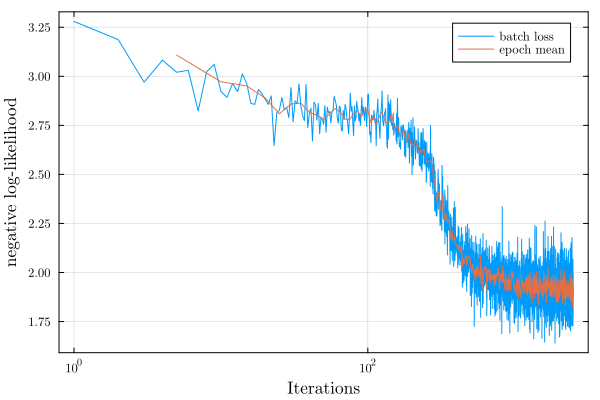

In [26]:
plot_loss(losses_rnade["circles"], length(data_2d_train_loaders["circles"]))
# plot(losses_rnade["circles"], fmt=:svg, label="", xlabel="Epoch", ylabel ="Negative log-likelihood")

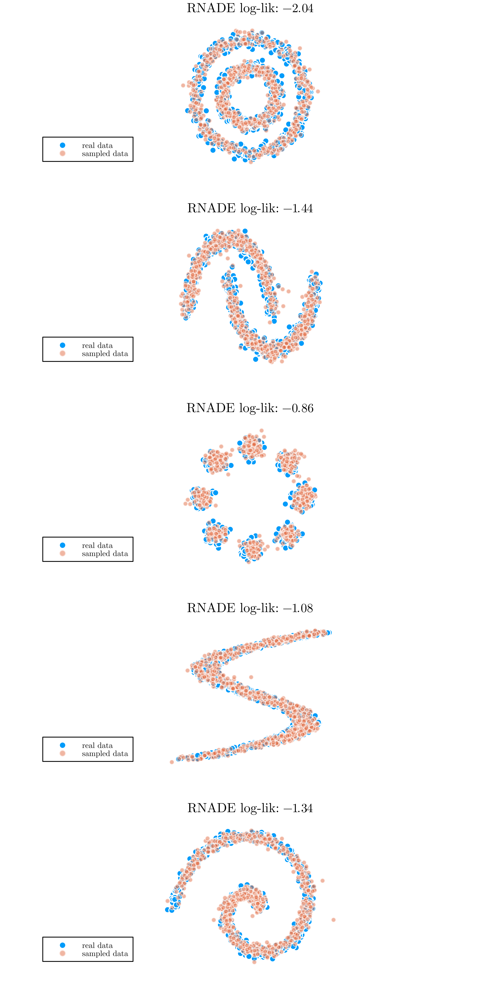

In [22]:
begin
	Random.seed!(1234)
    plts_with_masks = Dict()
    sample_size = 800
    for (name, model) in rnade_models_with_masks
        test_ll = logpdf(model, data_2d_test[name] |> device)
        plt = plot_samples(data_2d_test[name], sample(model, sample_size); alpha2 = 0.5, title="RNADE log-lik: "*L"%$(round(test_ll; digits=2))")
        plts_with_masks[name] = plt
    end

    plot(values(plts_with_masks)..., layout=(5,1), size=(580, 1200),titlefontsize=10, dpi=400, legendfontsize=6, legend=:bottomleft, fmt=:svg)
end

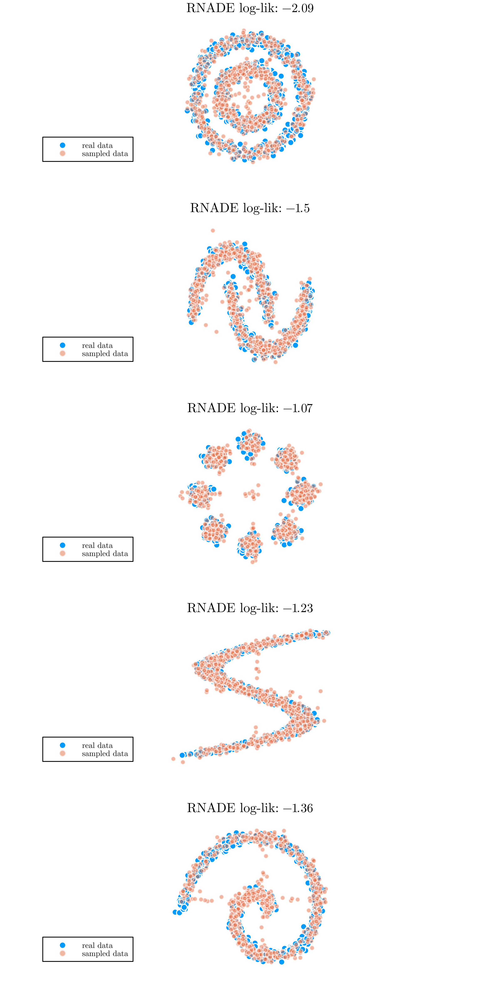

In [23]:
begin
	Random.seed!(1234)
    plts_without_masks = Dict()
    sample_size = 800
    for (name, model) in rnade_models_without_masks
        test_ll = logpdf(model, data_2d_test[name] |> device)
        plt = plot_samples(data_2d_test[name], sample(model, sample_size); alpha2 = 0.5, title="RNADE log-lik: "*L"%$(round(test_ll; digits=2))")
        plts_without_masks[name] = plt
    end

    plot(values(plts_without_masks)..., layout=(5,1), size=(580, 1200),titlefontsize=10, dpi=400, legendfontsize=6, legend=:bottomleft, fmt=:svg)
end